In [3]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
import os

In [4]:
ds = xr.load_dataset('/emmy-noether/home/mf671/Isca/exp/exeter_project_mf/input/qflux_30_72,90_tri.nc')

In [5]:
qflux = ds['ocean_qflux']
lat = ds['lat']
lon = ds['lon']

Text(0.5, 0, 'longitude')

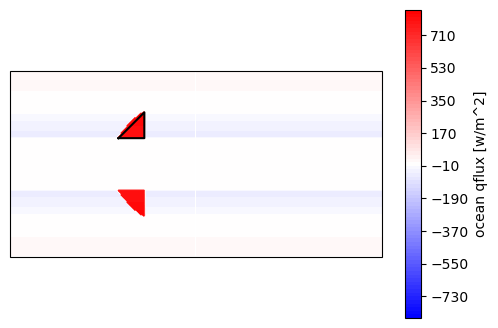

In [10]:
range = np.arange(-850,860,20)
plt.figure(figsize=(6,4))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-180, 180, -90, 90])  # Set map extent [min_lon, max_lon, min_lat, max_lat]

shad=ax.contourf(lon,lat,qflux,range,cmap='bwr')
plt.colorbar(shad,label = 'ocean qflux [w/m^2]')
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)
ax.plot(lons, lats, color='black', transform=ccrs.PlateCarree())
plt.ylabel('latitude')
plt.xlabel('longitude')

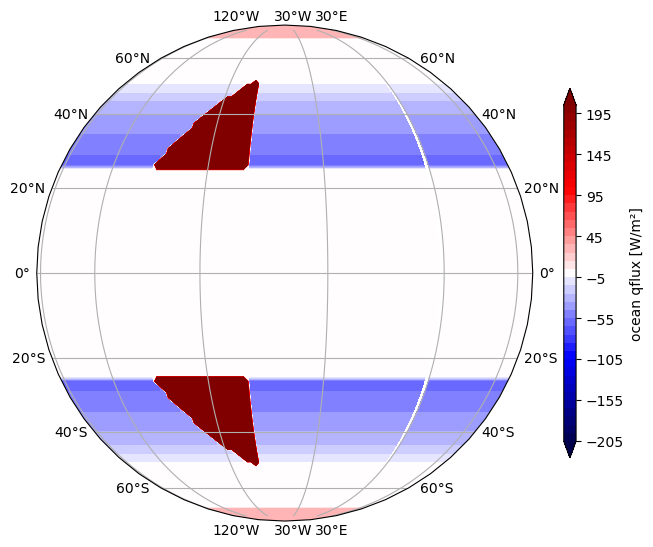

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Load data
ds = xr.load_dataset('/emmy-noether/home/mf671/Isca/exp/exeter_project_mf/input/qflux_30_72,90_tri.nc')
qflux = ds['ocean_qflux']
lat = ds['lat']
lon = ds['lon']

# Set contour levels
range = np.arange(-205, 210, 10)

# Create the plot with Orthographic projection (like a globe)
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.Orthographic(central_longitude=-40, central_latitude=0))

# Plot the data
contour = ax.contourf(lon, lat, qflux, range, cmap='seismic',extend='both', transform=ccrs.PlateCarree())

# Add colorbar
plt.colorbar(contour, ax=ax, orientation='vertical', pad=0.05, aspect=30,shrink=0.6, label='ocean qflux [W/m²]')

# Remove continent lines and borders (none added)
ax.set_global()  # Ensures full globe is visible
ax.gridlines(draw_labels=True)

#plt.title('Ocean Q-Flux (Globe View)')
plt.show()
